# Adjudication Results Analysis

This notebook analyzes the aggregate results produced by ExamBoard in `data/adjudication/adjudications.json`.

## Context & Methods

The unit of analysis is one adjudication decision. This notebook uses only the aggregate saved by ExamBoard and compares `a1`/`a2` decisions, disagreement types, correction approval, and RDF outcomes.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name in {'docs', 'ExamBoard'}:
    ROOT = ROOT.parent
RESULTS_FILE = ROOT / 'data' / 'adjudication' / 'adjudications.json'

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 80)
print(f'Source: {RESULTS_FILE}')

Source: D:\kg-construction-llm-evaluation\KGTestBench\data\adjudication\adjudications.json


## Data

### Load and validate

In [2]:
report = json.loads(RESULTS_FILE.read_text(encoding='utf-8-sig'))
required_report_keys = {'input_sha256', 'identifier', 'total', 'results'}
missing_report_keys = required_report_keys - report.keys()
assert not missing_report_keys, f'Missing report fields: {missing_report_keys}'
assert report['total'] == len(report['results']), 'total does not match the number of results'

results = pd.DataFrame(report['results'])
required_result_keys = {'case_id', 'identifier', 'source_case_id', 'disagreement_type', 'decision', 'status', 'approve_correction', 'rdf_outcome'}
missing_result_keys = required_result_keys - set(results.columns)
assert not missing_result_keys, f'Missing result fields: {missing_result_keys}'

results['selected'] = results['decision'].str.replace('accept_', '', regex=False)
results['approve_correction'] = results['approve_correction'].astype(bool)
print(f"Results loaded: {len(results):,}")
print(f"Report identifier: {report['identifier'] or 'all'}")
print(f"Input hash: {report['input_sha256']}")

Results loaded: 215
Report identifier: all
Input hash: 9e8be6125aceb0f2c3c9f98c9a224f2036b28be174738998f1956013c81332e0


In [3]:
results.head(10)

,case_id,identifier,source_case_id,disagreement_type,status,case_disagreement_types,decision,approve_correction,approved_ratings,approved_triples,rdf_outcome,selected
0,Amazon-multiple_disagreements-001,Amazon,csv-0001,multiple_disagreements,adjudicated,"[unilateral_unresolved_entities, shared_rejection_diagnosis_divergence]",accept_a2,False,None,[],original_rejected,a2
1,Amazon-shared_rejection_diagnosis_divergence-001,Amazon,csv-0002,shared_rejection_diagnosis_divergence,adjudicated,[shared_rejection_diagnosis_divergence],accept_a2,False,None,[],original_rejected,a2
2,Amazon-unilateral_unresolved_entities-001,Amazon,csv-0003,unilateral_unresolved_entities,adjudicated,[unilateral_unresolved_entities],accept_a2,False,None,[],original_rejected,a2
3,Amazon-unilateral_unresolved_entities-002,Amazon,csv-0004,unilateral_unresolved_entities,adjudicated,[unilateral_unresolved_entities],accept_a2,False,None,[],original_rejected,a2
4,Amazon-unilateral_unresolved_entities-003,Amazon,csv-0005,unilateral_unresolved_entities,adjudicated,[unilateral_unresolved_entities],accept_a2,False,None,[],original_rejected,a2
5,Amazon-shared_rejection_diagnosis_divergence-002,Amazon,csv-0006,shared_rejection_diagnosis_divergence,adjudicated,[shared_rejection_diagnosis_divergence],accept_a2,False,None,[],original_rejected,a2
6,Amazon-shared_rejection_diagnosis_divergence-003,Amazon,csv-0007,shared_rejection_diagnosis_divergence,adjudicated,[shared_rejection_diagnosis_divergence],accept_a2,False,None,[],original_rejected,a2
7,Amazon-shared_rejection_diagnosis_divergence-004,Amazon,csv-0008,shared_rejection_diagnosis_divergence,adjudicated,[shared_rejection_diagnosis_divergence],accept_a2,False,None,[],original_rejected,a2
8,Amazon-shared_rejection_diagnosis_divergence-005,Amazon,csv-0009,shared_rejection_diagnosis_divergence,adjudicated,[shared_rejection_diagnosis_divergence],accept_a2,False,None,[],original_rejected,a2
9,Amazon-unilateral_unresolved_entities-004,Amazon,csv-0010,unilateral_unresolved_entities,adjudicated,[unilateral_unresolved_entities],accept_a2,False,None,[],original_rejected,a2


## Results

### Volume and coverage

In [4]:
coverage = pd.DataFrame({
    'metric': ['results', 'identifiers', 'disagreement types', 'multiple-disagreement cases'],
    'value': [
        len(results),
        results['identifier'].nunique(),
        results['disagreement_type'].nunique(),
        results['disagreement_type'].eq('multiple_disagreements').sum(),
    ],
})
coverage

,metric,value
0,results,215
1,identifiers,10
2,disagreement types,3
3,multiple-disagreement cases,58


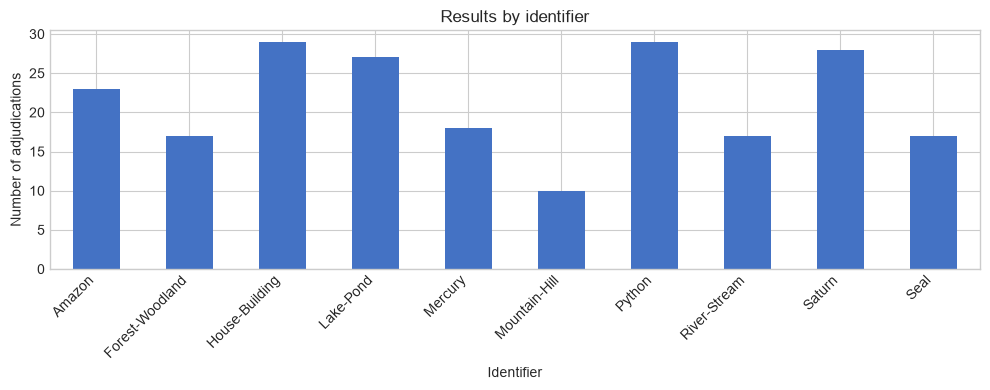

In [5]:
by_identifier = results['identifier'].value_counts().sort_index().rename('results')
ax = by_identifier.plot(kind='bar', figsize=(10, 4), color='#4472c4', title='Results by identifier')
ax.set_xlabel('Identifier')
ax.set_ylabel('Number of adjudications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Model decisions

In [6]:
decision_counts = results['selected'].value_counts().rename_axis('selected').to_frame('count')
decision_counts['percentage'] = (decision_counts['count'] / len(results) * 100).round(1)
decision_counts

,count,percentage
selected,,
a2,192,89.3
a1,23,10.7


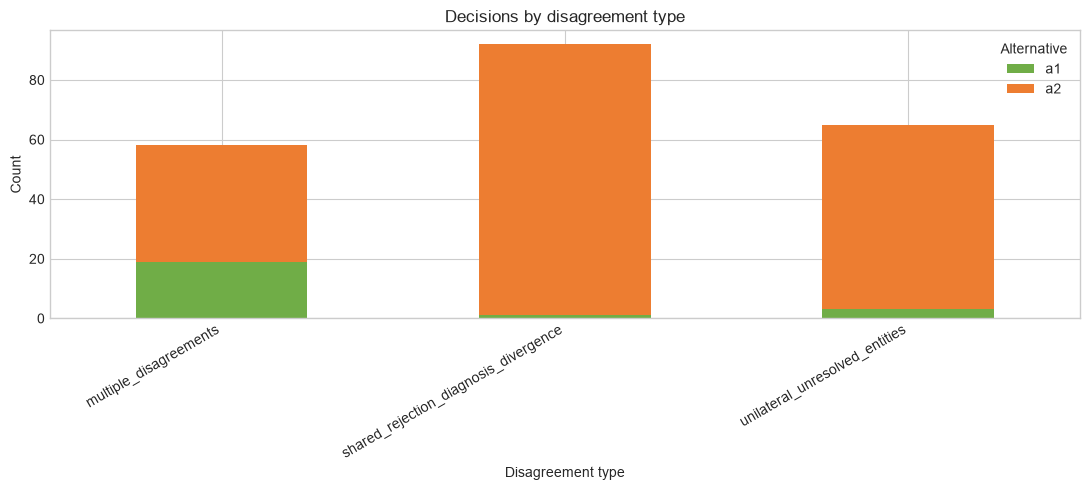

In [7]:
decision_by_type = pd.crosstab(results['disagreement_type'], results['selected'])
decision_by_type = decision_by_type.reindex(columns=['a1', 'a2'], fill_value=0)
ax = decision_by_type.plot(kind='bar', stacked=True, figsize=(11, 5), color=['#70ad47', '#ed7d31'], title='Decisions by disagreement type')
ax.set_xlabel('Disagreement type')
ax.set_ylabel('Count')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Alternative')
plt.tight_layout()
plt.show()

### Corrections and RDF outcomes

In [8]:
correction_summary = results['approve_correction'].value_counts().rename(index={False: 'not approved', True: 'approved'}).rename_axis('correction').to_frame('count')
rdf_summary = results['rdf_outcome'].value_counts().rename_axis('RDF outcome').to_frame('count')
display(correction_summary)
display(rdf_summary)

,count
correction,
not approved,215


,count
RDF outcome,
original_rejected,188
original_approved,27


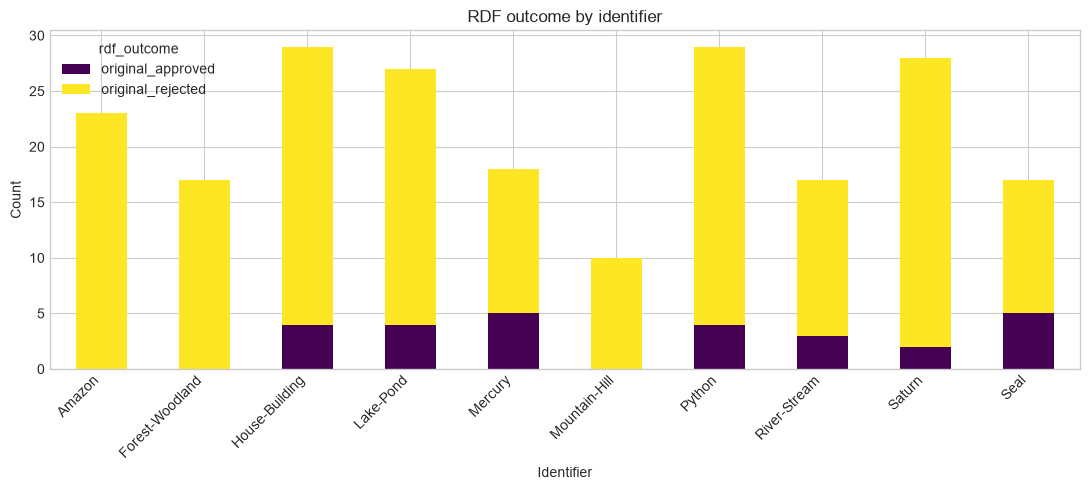

In [9]:
rdf_by_identifier = pd.crosstab(results['identifier'], results['rdf_outcome'])
rdf_by_identifier.plot(kind='bar', stacked=True, figsize=(11, 5), title='RDF outcome by identifier', colormap='viridis')
plt.xlabel('Identifier')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Identifier and disagreement type

This cross-tab shows how many adjudications selected A1 or A2 for each combination of `identifier` and `disagreement_type`. For `multiple_disagreements`, the selection is the final decision for the complete case.

In [10]:
decision_by_identifier_type = (
    results.groupby(['identifier', 'disagreement_type', 'selected'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=['a1', 'a2'], fill_value=0)
)
decision_by_identifier_type['total'] = decision_by_identifier_type.sum(axis=1)
decision_by_identifier_type.reset_index()

selected,identifier,disagreement_type,a1,a2,total
0,Amazon,multiple_disagreements,1,3,4
1,Amazon,shared_rejection_diagnosis_divergence,0,8,8
2,Amazon,unilateral_unresolved_entities,0,11,11
3,Forest-Woodland,multiple_disagreements,6,1,7
4,Forest-Woodland,shared_rejection_diagnosis_divergence,0,9,9
5,Forest-Woodland,unilateral_unresolved_entities,1,0,1
6,House-Building,multiple_disagreements,3,4,7
7,House-Building,shared_rejection_diagnosis_divergence,0,13,13
8,House-Building,unilateral_unresolved_entities,1,8,9
9,Lake-Pond,multiple_disagreements,1,8,9


## Takeaways

The points below are calculated from the loaded data, so they update when a new adjudication is run.

In [11]:
top_identifier = by_identifier.idxmax()
top_type = results['disagreement_type'].value_counts().idxmax()
top_decision = results['selected'].value_counts().idxmax()
approved_corrections = int(results['approve_correction'].sum())

print(f'- The identifier with the most results is {top_identifier!r}, with {int(by_identifier.max()):,} adjudications.')
print(f'- The most frequent disagreement type is {top_type!r}.')
print(f'- The most selected alternative was {top_decision!r}.')
print(f'- Explicitly approved corrections: {approved_corrections:,}.')
print('- Interpret the results as choices between human alternatives; the model does not create a third alternative.')

- The identifier with the most results is 'House-Building', with 29 adjudications.
- The most frequent disagreement type is 'shared_rejection_diagnosis_divergence'.
- The most selected alternative was 'a2'.
- Explicitly approved corrections: 0.
- Interpret the results as choices between human alternatives; the model does not create a third alternative.
